# Spectral Scale Selection for Gaussian KDE

This notebook implements the experiment for samples
$X_1,\dots,X_n \sim N(0,\sigma^2)$ and Gaussian kernel density estimators.

For a bandwidth grid $0<h_1<\dots<h_N$, we build

$$
S_\gamma(\hat f_{h_i},\hat f_{h_j})
=\exp\left(-\gamma\lVert \hat f_{h_i}-\hat f_{h_j}\rVert_2^2\right)
$$

using the exact Gaussian-kernel formula

$$
D_{ij}=I_{ii}+I_{jj}-2I_{ij},\qquad
I_{ij}=\frac{1}{n^2}\frac{1}{\sqrt{2\pi(h_i^2+h_j^2)}}
\sum_{k,l=1}^{n}\exp\left(-\frac{(X_k-X_l)^2}{2(h_i^2+h_j^2)}\right).
$$

The selected spectral bandwidth is the grid point where the Perron vector of $S_\gamma$ is maximal.
Since the true density is known in this simulation, we compare it to the oracle bandwidth

$$
h_{oracle}=\arg\min_{h_i}\int \left(\hat f_{h_i}(x)-f(x)\right)^2\,dx.
$$


In [29]:
from __future__ import annotations

import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib-cache"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)


## Exact Gaussian formulas

All matrix entries and oracle errors below are computed exactly for the one-dimensional Gaussian
kernel and the true density $N(0,\sigma^2)$.

## One sample sanity check

The first run compares the spectral selector and the oracle selector on one independent sample.

## Empirical distribution of chosen bandwidths

This follows the plotting style of the earlier KDE notebook: repeated independent samples give one
oracle index and one spectral index each, and the plot shows their relative frequencies on the same
bandwidth grid.

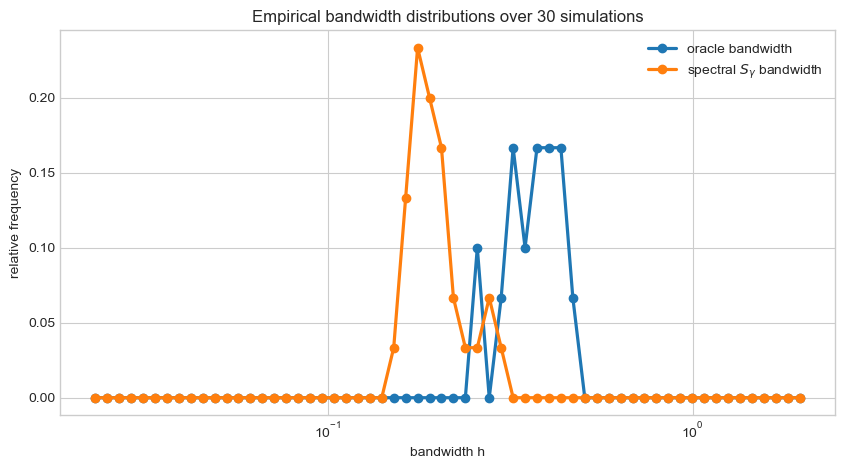

Fixed-n oracle versus spectral experiment
------------------------------------------
Data distribution: X_i ~ N(0, 1)
Sample size per simulation: n = 200
Number of simulations: R = 30
Bandwidth grid size: n_h_distribution = 60
Gamma rule: auto

Bandwidth summaries
-------------------
modal oracle h:   0.321903
modal spectral h: 0.176179
median oracle h:  0.374255
median spectral h:0.189966
mean oracle h:    0.367372
mean spectral h:  0.199708

Grid-index agreement
--------------------
Exact same grid index: 0.00%
Within 1 grid step:   0.00%
Within 2 grid steps:  0.00%


,seed,oracle_index,spectral_index,oracle_h,spectral_h,oracle_l2_error,spectral_l2_error,gamma
0,90000,37,26,0.374255,0.163393,0.072468,0.087993,76.181909
1,90001,39,28,0.435122,0.189966,0.068087,0.123564,48.665794
2,90002,38,27,0.403543,0.176179,0.047189,0.080251,58.241021
3,90003,34,28,0.298541,0.189966,0.054280,0.061076,67.996237
4,90004,37,26,0.374255,0.163393,0.042027,0.065395,63.992216


In [32]:
# Pilot defaults. Increase num_simulations_distribution and n_h_distribution for final runs.
n_distribution = 200
sigma2_distribution = 1.0
num_simulations_distribution = 30
n_h_distribution = 60
base_seed_distribution = 90_000
gamma_distribution = "auto"


def run_one_spectral_vs_oracle_experiment(
    seed: int,
    n: int,
    sigma2: float,
    h_grid: np.ndarray,
    gamma: float | str = "auto",
) -> dict[str, float | int]:
    rng = np.random.default_rng(seed)
    samples = rng.normal(loc=0.0, scale=np.sqrt(sigma2), size=n)

    ise_values_current = exact_oracle_ise_values(samples=samples, h_grid=h_grid, sigma2=sigma2)
    oracle_index = int(np.argmin(ise_values_current))

    spectral_current = select_spectral_bandwidth(samples=samples, h_grid=h_grid, gamma=gamma)
    spectral_index = int(spectral_current["selected_index"])

    return {
        "seed": seed,
        "oracle_index": oracle_index,
        "spectral_index": spectral_index,
        "oracle_h": float(h_grid[oracle_index]),
        "spectral_h": float(h_grid[spectral_index]),
        "oracle_l2_error": float(np.sqrt(max(ise_values_current[oracle_index], 0.0))),
        "spectral_l2_error": float(np.sqrt(max(ise_values_current[spectral_index], 0.0))),
        "gamma": float(spectral_current["gamma"]),
    }


h_grid_distribution = bandwidth_grid_for_gaussian_experiment(
    n=n_distribution,
    sigma2=sigma2_distribution,
    n_h=n_h_distribution,
)

bandwidth_distribution_results = [
    run_one_spectral_vs_oracle_experiment(
        seed=base_seed_distribution + simulation,
        n=n_distribution,
        sigma2=sigma2_distribution,
        h_grid=h_grid_distribution,
        gamma=gamma_distribution,
    )
    for simulation in range(num_simulations_distribution)
]

distribution_results = pd.DataFrame(bandwidth_distribution_results)

oracle_indices = distribution_results["oracle_index"].to_numpy(dtype=int)
spectral_indices = distribution_results["spectral_index"].to_numpy(dtype=int)

oracle_relative_frequencies = np.bincount(
    oracle_indices,
    minlength=len(h_grid_distribution),
) / num_simulations_distribution
spectral_relative_frequencies = np.bincount(
    spectral_indices,
    minlength=len(h_grid_distribution),
) / num_simulations_distribution

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    h_grid_distribution,
    oracle_relative_frequencies,
    marker="o",
    lw=2.3,
    label="oracle bandwidth",
)
ax.plot(
    h_grid_distribution,
    spectral_relative_frequencies,
    marker="o",
    lw=2.3,
    label=r"spectral $S_\gamma$ bandwidth",
)
ax.set_xscale("log")
ax.set_title(f"Empirical bandwidth distributions over {num_simulations_distribution} simulations")
ax.set_xlabel("bandwidth h")
ax.set_ylabel("relative frequency")
ax.legend()
plt.show()

exact_match_rate = np.mean(spectral_indices == oracle_indices)
within_1_rate = np.mean(np.abs(spectral_indices - oracle_indices) <= 1)
within_2_rate = np.mean(np.abs(spectral_indices - oracle_indices) <= 2)

print("Fixed-n oracle versus spectral experiment")
print("------------------------------------------")
print(f"Data distribution: X_i ~ N(0, {sigma2_distribution:g})")
print(f"Sample size per simulation: n = {n_distribution}")
print(f"Number of simulations: R = {num_simulations_distribution}")
print(f"Bandwidth grid size: n_h_distribution = {n_h_distribution}")
print(f"Gamma rule: {gamma_distribution}")
print()
print("Bandwidth summaries")
print("-------------------")
print(f"modal oracle h:   {h_grid_distribution[int(np.argmax(oracle_relative_frequencies))]:.6g}")
print(f"modal spectral h: {h_grid_distribution[int(np.argmax(spectral_relative_frequencies))]:.6g}")
print(f"median oracle h:  {distribution_results['oracle_h'].median():.6g}")
print(f"median spectral h:{distribution_results['spectral_h'].median():.6g}")
print(f"mean oracle h:    {distribution_results['oracle_h'].mean():.6g}")
print(f"mean spectral h:  {distribution_results['spectral_h'].mean():.6g}")
print()
print("Grid-index agreement")
print("--------------------")
print(f"Exact same grid index: {exact_match_rate:.2%}")
print(f"Within 1 grid step:   {within_1_rate:.2%}")
print(f"Within 2 grid steps:  {within_2_rate:.2%}")

distribution_results.head()


## Consistency analysis across sample sizes

For $n=50,100,150,\dots,1000$, this block repeats the oracle and spectral selections and plots
the full observed range across simulations. The shaded bands are bounded by the minimum and maximum
values over repetitions for each sample size.

## Notes

- The only data-generating model in this notebook is $N(0,\sigma^2)$.
- The comparison target is the exact oracle bandwidth on the same finite grid, not Silverman's rule.
- `gamma="auto"` rescales each sample's distance matrix so the median positive distance maps to $e^{-1}$.
  Replace it by a fixed number to study sensitivity to the monotone transform.
- The repeated-bandwidth distribution plot intentionally mirrors the earlier KDE notebook: relative
  frequencies over bandwidth grid points, with oracle and spectral choices shown as two curves.

## Extended consistency analysis: n = 100, 200, ..., 2000

This repeats the same min-max consistency analysis on the coarser sample-size grid
$n=100,200,\dots,2000$ and adds the JS quadrature selector from the earlier KDE notebook.

## KDEs selected by different similarity rules

This block draws the KDEs selected by the rules currently considered in the notebook:

- exact oracle ISE;
- JS quadrature;
- $S_\gamma(f,g)=\exp(-\gamma\|f-g\|_2^2)$;
- TV overlap $1-d_{TV}(f,g)=\int \min\{f,g\}$;
- Hellinger affinity $1-d_H(f,g)=\int \sqrt{fg}$.

The TV and Hellinger matrices are computed on the same quadrature grid as the JS matrix.

## Empirical bandwidth distributions for all five rules

This repeats the bandwidth-selection experiment over 100 independent samples and plots the empirical
distribution of selected bandwidths for all five rules on the same bandwidth grid.